# Análisis de fallas APS en camiones Scania mediante PCA

**Inteligencia Artificial I · Actividad 3 · Grupo 5**

**Integrantes:** Santiago Camacho Parra · Jonathan Pedroza Bernal · Juan Fernando Bueno Torres

[**Abrir la aplicación en Streamlit**](https://actividad3-ngxciwry9uexzaahrfigdl.streamlit.app/) · [**Repositorio del proyecto**](https://github.com/ProyectoCorte3/Actividad3)

Este notebook presenta y analiza **resultados reales del entrenamiento guardados en el repositorio** en `models/metricas.json`. Los cálculos y gráficos de las celdas se ejecutaron y quedaron guardados aquí, por lo que se pueden consultar desde GitHub o VS Code. El entrenamiento original que produjo los resultados se encuentra en `entrenar.py`; para repetirlo con los CSV se utiliza el proyecto completo.

## 1. Datos originales y resultados del entrenamiento

El conjunto [APS Failure at Scania Trucks, UCI](https://archive.ics.uci.edu/dataset/421/aps+failure+at+scania+trucks) contiene registros operativos reales y anonimizados. La clase `pos` indica falla relacionada con APS y `neg` indica falla de otro componente.

Las cifras que siguen corresponden a `models/metricas.json` del repositorio del Grupo 5, generado el 22 de noviembre de 2026. Conservamos esas cifras tal como quedaron registradas.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

# Estadísticas verificadas en ProyectoCorte3/Actividad3, models/metricas.json.
# Se usan directamente los resultados reales ya calculados por el entrenamiento.
resultados = {
    'registros_originales': 60000,
    'variables_originales': 170,
    'registros_positivos': 1000,
    'registros_negativos': 59000,
    'registros_prueba_independiente': 16000,
    'celdas_sin_dato': 850015,
    'filas_con_faltantes': 59409,
    'columnas_con_faltantes': 169,
    'duplicados_completos': 0,
    'registros_entrenamiento': 48000,
    'registros_validacion': 12000,
    'columnas_tras_limpieza': 162,
    'componentes_pca': 20,
    'varianza_pca': 0.6523771977287186,
    'accuracy': 0.9660833333333333,
    'precision_aps': 0.3230769230769231,
    'recall_aps': 0.945,
    'f1_aps': 0.48152866242038217,
    'roc_auc': 0.9852597457627119,
    'tn': 11404, 'fp': 396, 'fn': 11, 'tp': 189,
}
print('Fuente: models/metricas.json de ProyectoCorte3/Actividad3')
print('Registros originales:', f"{resultados['registros_originales']:,}")
print('Variables originales:', resultados['variables_originales'])
print('Entrenamiento:', f"{resultados['registros_entrenamiento']:,}", '| Validación:', f"{resultados['registros_validacion']:,}")
print('Archivo independiente para demostración:', f"{resultados['registros_prueba_independiente']:,}")

Fuente: models/metricas.json de ProyectoCorte3/Actividad3
Registros originales: 60,000
Variables originales: 170
Entrenamiento: 48,000 | Validación: 12,000
Archivo independiente para demostración: 16,000


## 2. Exploración inicial: distribución de categorías

Las dos categorías están muy desbalanceadas: la mayoría de los registros corresponde a fallas no relacionadas con APS. Este punto es clave para interpretar la evaluación: un accuracy alto no garantiza una buena identificación de la clase menos frecuente.

,Registros,Porcentaje
No APS (neg),59000,98.33
APS (pos),1000,1.67


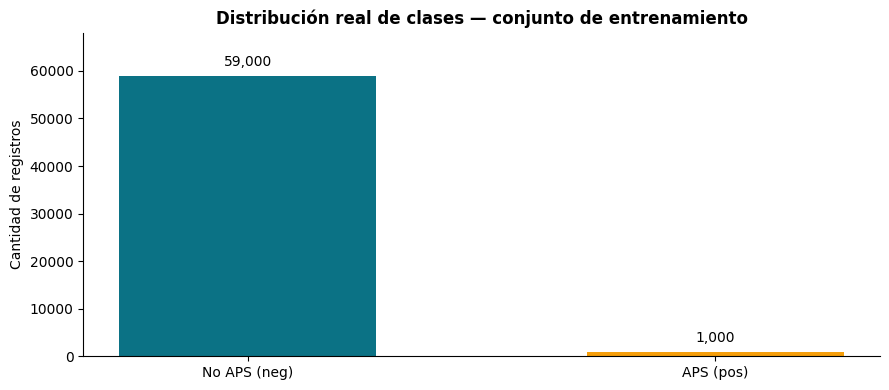

In [2]:
conteos = pd.Series({'No APS (neg)': resultados['registros_negativos'],
                      'APS (pos)': resultados['registros_positivos']})
display(pd.DataFrame({'Registros': conteos, 'Porcentaje': (100 * conteos / conteos.sum()).round(2)}))
fig, ax = plt.subplots(figsize=(9, 4))
colores = ['#0b7285', '#f59e0b']
barras = ax.bar(conteos.index, conteos.values, color=colores, width=.55)
ax.bar_label(barras, labels=[f'{v:,.0f}' for v in conteos.values], padding=5)
ax.set_title('Distribución real de clases — conjunto de entrenamiento', weight='bold')
ax.set_ylabel('Cantidad de registros')
ax.set_ylim(0, 68000)
ax.spines[['top','right']].set_visible(False)
plt.tight_layout()
plt.show()

## 3. Calidad de datos y limpieza

La base tiene **850.015 valores faltantes** y **cero filas duplicadas completas**. El entrenamiento descarta columnas con 50 % o más de valores ausentes, completa los faltantes restantes con la mediana y estandariza las variables.

Las transformaciones se aprenden con los datos de entrenamiento, no con los de validación.

In [3]:
calidad = pd.DataFrame({
    'Indicador': ['Celdas sin dato', 'Filas con al menos un faltante',
                  'Columnas con algún faltante', 'Duplicados completos',
                  'Columnas conservadas tras el filtro'],
    'Valor': [resultados['celdas_sin_dato'], resultados['filas_con_faltantes'],
              resultados['columnas_con_faltantes'], resultados['duplicados_completos'],
              resultados['columnas_tras_limpieza']]
})
display(calidad)
print('Porcentaje de registros con algún dato faltante:',
      f"{100*resultados['filas_con_faltantes']/resultados['registros_originales']:.2f}%")

,Indicador,Valor
0,Celdas sin dato,850015
1,Filas con al menos un faltante,59409
2,Columnas con algún faltante,169
3,Duplicados completos,0
4,Columnas conservadas tras el filtro,162


Porcentaje de registros con algún dato faltante: 99.02%


### Variables con mayor cantidad de valores ausentes

Estas cuentas se obtuvieron del diagnóstico real que está guardado en `models/metricas.json`. Los nombres de las variables son códigos anonimizados, no nombres de sensores conocidos.

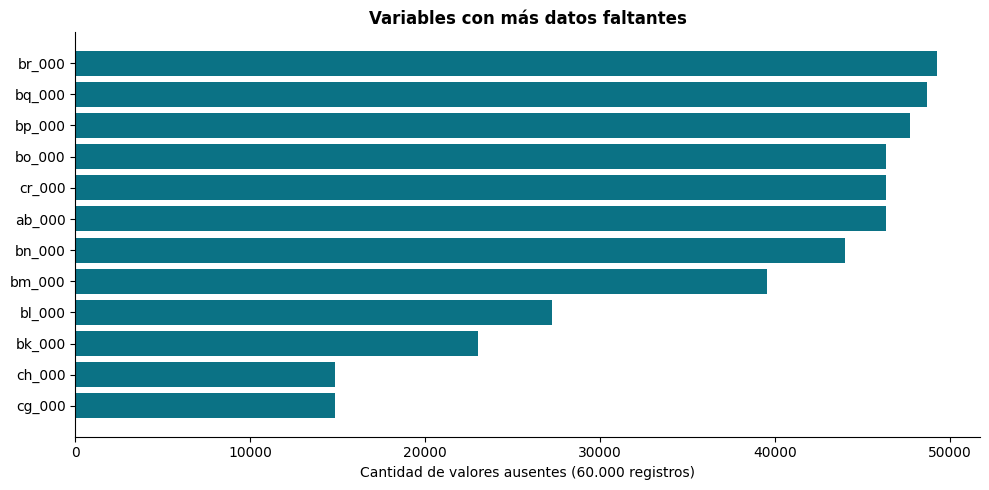

Total de valores faltantes en todas las columnas: 850,015


In [4]:
nulos_principales = {
    'br_000':49264, 'bq_000':48722, 'bp_000':47740, 'bo_000':46333,
    'ab_000':46329, 'cr_000':46329, 'bn_000':44009, 'bm_000':39549,
    'bl_000':27277, 'bk_000':23034, 'cg_000':14861, 'ch_000':14861
}
serie = pd.Series(nulos_principales).sort_values()
fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(serie.index, serie.values, color='#0b7285')
ax.set_xlabel('Cantidad de valores ausentes (60.000 registros)')
ax.set_title('Variables con más datos faltantes', weight='bold')
ax.spines[['top','right']].set_visible(False)
plt.tight_layout(); plt.show()
print('Total de valores faltantes en todas las columnas:', f"{resultados['celdas_sin_dato']:,}")

## 4. División para entrenamiento y validación

Se utilizaron **48.000 registros para ajustar el modelo** y **12.000 para validar sus predicciones**. Además hay **16.000 registros independientes** que utiliza la aplicación para mostrar ejemplos. Las métricas de este informe corresponden a los **12.000 de validación**, no a esos 16.000.

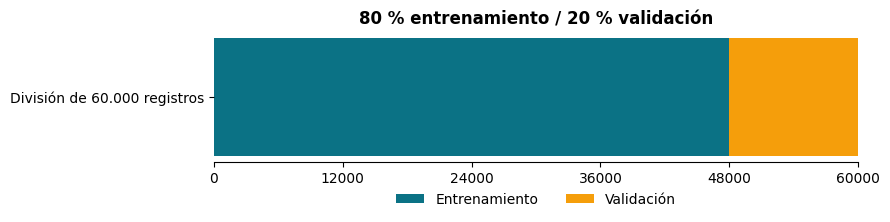

In [5]:
division = pd.Series({'Entrenamiento': resultados['registros_entrenamiento'],
                      'Validación': resultados['registros_validacion']})
fig, ax = plt.subplots(figsize=(9, 2.4))
ax.barh(['División de 60.000 registros'], [division.iloc[0]], color='#0b7285', label='Entrenamiento')
ax.barh(['División de 60.000 registros'], [division.iloc[1]],
        left=[division.iloc[0]], color='#f59e0b', label='Validación')
ax.legend(loc='upper center', bbox_to_anchor=(.5, -.14), ncol=2, frameon=False)
ax.set_xlim(0, 60000)
ax.set_xticks([0, 12000, 24000, 36000, 48000, 60000])
ax.set_title('80 % entrenamiento / 20 % validación', weight='bold')
ax.spines[['top','right','left']].set_visible(False)
plt.tight_layout(); plt.show()

## 5. ¿Qué hizo PCA en el modelo?

El algoritmo **PCA (Análisis de Componentes Principales)** redujo las **162 variables conservadas después de la preparación** a **20 componentes principales**. Según el registro del entrenamiento, estas componentes explican en conjunto **65,24 % de la varianza**.

La clasificación final se realiza con regresión logística; PCA por sí solo no predice la categoría de falla.

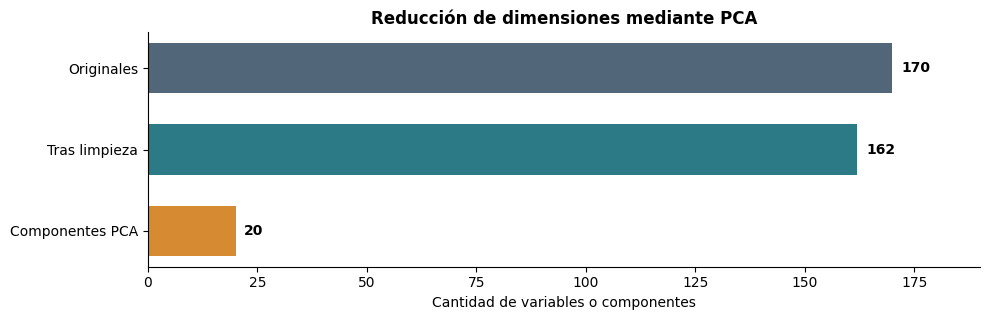

Varianza explicada acumulada por las 20 componentes: 65.24%
Porcentaje restante de varianza: 34.76%


In [6]:
pasos = [('Originales',170),('Tras limpieza',162),('Componentes PCA',20)]
fig, ax = plt.subplots(figsize=(10, 3.3))
for i, (nombre, n) in enumerate(pasos):
    ax.barh(i,n,color=['#52667a','#2b7a85','#d68b33'][i],height=.62)
    ax.text(n+2,i,str(n),va='center',weight='bold')
ax.set_yticks(range(3),[x[0] for x in pasos]);ax.invert_yaxis()
ax.set_xlim(0,190);ax.set_xlabel('Cantidad de variables o componentes')
ax.set_title('Reducción de dimensiones mediante PCA',weight='bold')
ax.spines[['top','right']].set_visible(False)
plt.tight_layout();plt.show()
print(f"Varianza explicada acumulada por las 20 componentes: {resultados['varianza_pca']*100:.2f}%")
print('Porcentaje restante de varianza:',f"{(1-resultados['varianza_pca'])*100:.2f}%")

## 6. Pipeline del modelo

El código de `entrenar.py` guarda un único pipeline con **selección de columnas → mediana → estandarización → PCA de 20 componentes → regresión logística**.

El modelo serializado está en `models/modelo_pca_scania.joblib`, acompañado por los resultados en `models/metricas.json`.

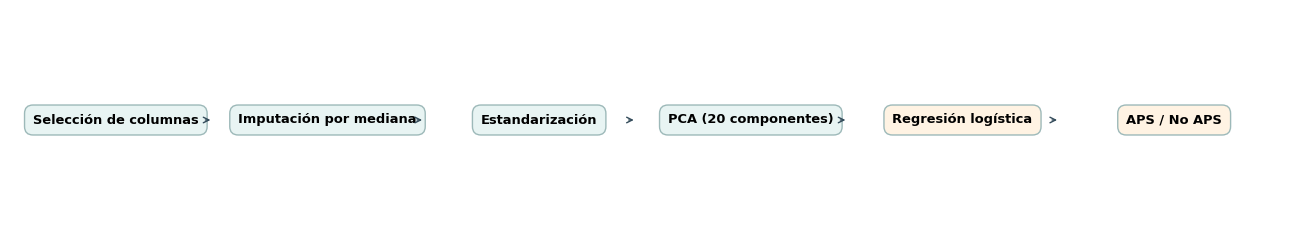

In [7]:
fases = ['Selección de columnas', 'Imputación por mediana', 'Estandarización',
         'PCA (20 componentes)', 'Regresión logística', 'APS / No APS']
fig, ax = plt.subplots(figsize=(13, 2.5))
ax.set_xlim(0, len(fases));ax.set_ylim(0, 1);ax.axis('off')
for i, frase in enumerate(fases):
    ax.text(i+.5,.5,frase,ha='center',va='center',fontsize=9.4,weight='bold',
            bbox=dict(boxstyle='round,pad=0.65',fc=('#e8f4f3' if i<4 else '#fff3e3'),ec='#9db9b9'))
    if i<len(fases)-1:ax.annotate('',xy=(i+.96,.5),xytext=(i+.91,.5),arrowprops={'arrowstyle':'->','color':'#334b5a'})
plt.tight_layout();plt.show()

## 7. Evaluación y matriz de confusión

En la validación de 12.000 registros, se detectaron **189 de 200 fallas APS**. Se registraron **396 falsas alarmas APS**, por eso la precisión de la clase positiva es menor que el accuracy total.

,Predicho: No APS,Predicho: APS
Real: No APS,11404,396
Real: APS,11,189


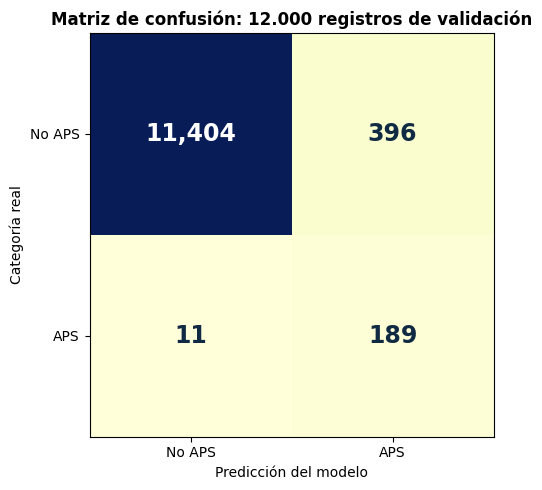

In [8]:
tn, fp, fn, tp = (resultados[k] for k in ['tn','fp','fn','tp'])
matriz = pd.DataFrame([[tn,fp],[fn,tp]],
                       index=['Real: No APS','Real: APS'],
                       columns=['Predicho: No APS','Predicho: APS'])
display(matriz)
fig, ax = plt.subplots(figsize=(7, 5))
im = ax.imshow([[tn,fp],[fn,tp]],cmap='YlGnBu')
ax.set_xticks([0,1],['No APS','APS']); ax.set_yticks([0,1],['No APS','APS'])
ax.set_xlabel('Predicción del modelo');ax.set_ylabel('Categoría real')
for i in range(2):
    for j in range(2):
        v=[[tn,fp],[fn,tp]][i][j]
        ax.text(j,i, f'{v:,}',ha='center',va='center',fontsize=17,weight='bold',color=('white' if v>3000 else '#102a43'))
ax.set_title('Matriz de confusión: 12.000 registros de validación',weight='bold')
plt.tight_layout();plt.show()

### Métricas verificadas con la matriz real

Recalculamos exactitud, precisión, recall y F1 a partir de los cuatro valores de la matriz de confusión. El ROC AUC se toma directamente del archivo de resultados porque no puede reconstruirse únicamente con esa matriz.

,Valor,Porcentaje
Accuracy,0.9661,96.61
Precisión APS,0.3231,32.31
Recall APS,0.9450,94.50
F1 APS,0.4815,48.15
ROC AUC (resultado guardado),0.9853,98.53


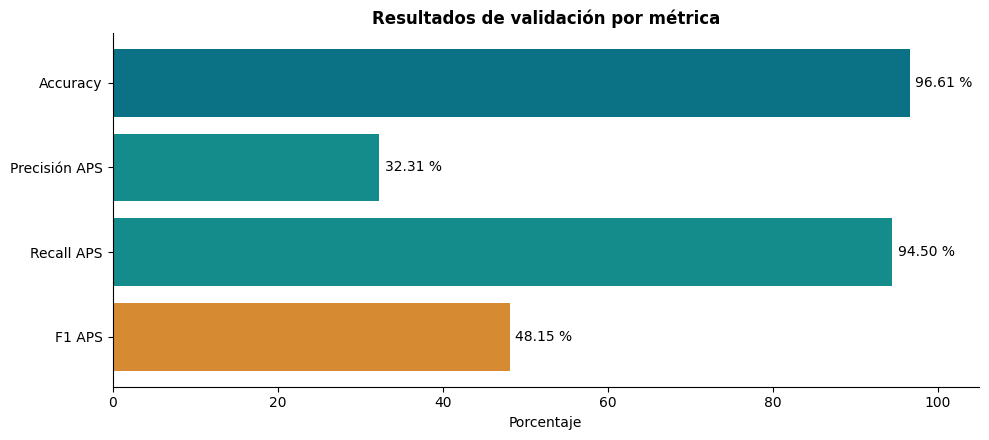

Las métricas recalculadas coinciden con las registradas en GitHub.


In [9]:
accuracy_calc = (tn+tp)/(tn+fp+fn+tp)
precision_calc = tp/(tp+fp)
recall_calc = tp/(tp+fn)
f1_calc = 2*precision_calc*recall_calc/(precision_calc+recall_calc)
metricas = pd.Series({
    'Accuracy':accuracy_calc,
    'Precisión APS':precision_calc,
    'Recall APS':recall_calc,
    'F1 APS':f1_calc,
    'ROC AUC (resultado guardado)':resultados['roc_auc']
})
display(pd.DataFrame({'Valor':metricas.round(4),'Porcentaje':(metricas*100).round(2)}))
assert abs(accuracy_calc - resultados['accuracy']) < 1e-10
assert abs(precision_calc - resultados['precision_aps']) < 1e-10
assert abs(recall_calc - resultados['recall_aps']) < 1e-10
assert abs(f1_calc - resultados['f1_aps']) < 1e-10
fig, ax = plt.subplots(figsize=(10, 4.5))
vars_ = metricas.iloc[:4]*100
b=ax.barh(vars_.index[::-1],vars_.values[::-1],color=['#d68b33','#148c8c','#148c8c','#0b7285'])
ax.bar_label(b,labels=[f'{v:.2f} %' for v in vars_.values[::-1]],padding=4)
ax.set_xlim(0,105);ax.set_xlabel('Porcentaje')
ax.set_title('Resultados de validación por métrica',weight='bold')
ax.spines[['top','right']].set_visible(False)
plt.tight_layout();plt.show()
print('Las métricas recalculadas coinciden con las registradas en GitHub.')

## 8. Interpretación de los resultados

El modelo tuvo una **exactitud global de 96,61 %**, pero la **precisión para APS fue 32,31 %**, lo que nos indica que genera varias alertas incorrectas. Aun así, el **recall APS de 94,50 %** muestra que identificó la mayoría de los casos APS en la validación.

Son dos aspectos distintos y ambos son importantes para evaluar el modelo. El objetivo del trabajo es entender esta diferencia y explicar con claridad cómo se comporta la clasificación.

In [10]:
total_alertas = tp + fp
print(f'Casos APS reales en validación: {tp+fn}')
print(f'APS detectados correctamente: {tp}')
print(f'APS que no se detectaron: {fn}')
print(f'Alertas APS emitidas por el modelo: {total_alertas}')
print(f'Alertas APS incorrectas: {fp}')
print(f'De cada 100 alertas APS, aproximadamente {round(100*tp/total_alertas)} corresponden a APS reales.')

Casos APS reales en validación: 200
APS detectados correctamente: 189
APS que no se detectaron: 11
Alertas APS emitidas por el modelo: 585
Alertas APS incorrectas: 396
De cada 100 alertas APS, aproximadamente 32 corresponden a APS reales.


## 9. Aplicación y demostración

La aplicación pública permite elegir un registro del conjunto de **16.000 registros independientes**, consultar tres indicadores numéricos editables y pulsar **Analizar registro**.

Durante la prueba de navegación se obtuvieron estos dos ejemplos reales: `Ejemplo A` fue clasificado como **No APS** con puntuación APS de **4,3 %** y `Ejemplo B` como **APS** con puntuación APS mostrada de **100,0 %** (redondeada). Son dos ejemplos individuales, no una evaluación general del conjunto de prueba.

**[Abrir Streamlit y probar la aplicación](https://actividad3-ngxciwry9uexzaahrfigdl.streamlit.app/)**

In [11]:
ejemplos = pd.DataFrame([
    {'Ejemplo':'A','Etiqueta real':'No APS','Predicción':'No APS','Puntuación APS mostrada':'4,3 %'},
    {'Ejemplo':'B','Etiqueta real':'APS','Predicción':'APS','Puntuación APS mostrada':'100,0 % (redondeado)'},
])
display(ejemplos)
print('Aplicación: https://actividad3-ngxciwry9uexzaahrfigdl.streamlit.app/')
print('Repositorio: https://github.com/ProyectoCorte3/Actividad3')

,Ejemplo,Etiqueta real,Predicción,Puntuación APS mostrada
0,A,No APS,No APS,"4,3 %"
1,B,APS,APS,"100,0 % (redondeado)"


Aplicación: https://actividad3-ngxciwry9uexzaahrfigdl.streamlit.app/
Repositorio: https://github.com/ProyectoCorte3/Actividad3


## 10. ¿Cómo repetir el entrenamiento completo?

El entrenamiento con las **60.000 filas reales** se implementó en `entrenar.py`, y los datos originales se encuentran en `data/raw/` del repositorio.

Para reproducirlo desde una terminal abierta en la carpeta principal de `Actividad3`:

```bat
python -m pip install -r requirements.txt
python entrenar.py
python -m streamlit run app/app.py
```

Al ejecutar `entrenar.py` se actualizan `models/modelo_pca_scania.joblib`, `models/metricas.json` y `docs/INFORME_AVANCE_REAL.txt` con los resultados de esa ejecución. El notebook presente documenta y visualiza los **resultados reales que ya fueron guardados por el entrenamiento existente**.

**Fuente:** Scania, *APS Failure at Scania Trucks*, UCI Machine Learning Repository, DOI [10.24432/C51S51](https://doi.org/10.24432/C51S51).

**Equipo:** Santiago Camacho Parra, Jonathan Pedroza Bernal y Juan Fernando Bueno Torres.